### Recovering the symbol from a travelling Whitham waves

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

In [2]:
from solvers.spectral import WhithamNewton
from solvers.pde import Whitham
from solvers.lsm import LSM
from solvers.help import *

from waves.waveGen import WhithamPacket

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [3]:
P           = 4* np.pi
amps = np.linspace(0.01,0.15,5)
means = np.zeros_like(amps)

N           = 2**6

dt = 5e-3
T = 3

In [4]:
x = np.linspace(0,P,N)

In [5]:
kdvp = WhithamPacket(P=P,N=N,amp_list=amps, mean_list=means, dt = dt, T= T)
H = kdvp.mainloop()

In [6]:
lsm = LSM(eta_list=H, dt = dt, P = P)
X = lsm.lsm()

In [7]:
ell, n = lsm.fit_symbol()
print(fit_table(ell,n,part='real'))


          ξ^3       ξ^2       ξ^1       ξ^0
ell  0.000081 -0.000665 -0.008884  1.395580
n   -0.000025 -0.001152  0.002764 -0.086389


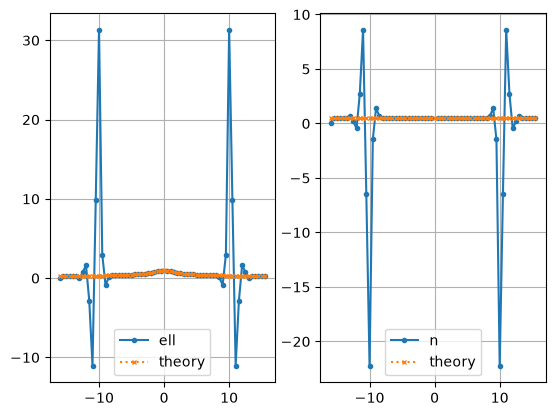

In [8]:
w = Whitham(P=P, dt=dt, T=T, u0 = H[0][0])
lsm.plot_symbol_fit(ell_t=w.dispersion)